# ParmaCRPrimaryGen: 宇宙線の一次粒子(PARMA のフラックス)

PARMA で計算した宇宙線のフラックス(エネルギー × 天頂角の分布)に従って、一次粒子を作ります。設定ファイルの `source` の節です。

| | |
| --- | --- |
| SMILE_tool_box | `SMILE_2p_PA_CR`(sim.mac の `SourceType CR`, `CR_FluxFile`, `ParaSrcSize`, `ParaSrcDistance`) |
| ソース | `simulation_source/modules/ParmaCRPrimaryGen/` |
| 基底クラス | anlgeant4 の `BasicPrimaryGen` |

点線源などは anlgeant4 の既製のモジュール(`PointSourcePrimaryGen`, `PlaneWavePrimaryGen` など)を `source` に書きます(`config/simulation/smile2p_ground_cs137.json`)。

## 1. 何をするか

1. 初期化: フラックスの ROOT ファイルから粒子の TH2D(`h2d0` 中性子、`h2d1` 陽子、`h2d31` 電子、`h2d32` 陽電子、`h2d33` ガンマ線。`../../../5_PARMAFlux/`)を読み、
   各ビンの「中身 [/cm²/s/sr/MeV] × dE × dcosθ × 2π」の累積分布を作る。全体の和が `TotalFlux()` [/cm²/s]。
2. イベントごと:
   1. 累積分布から (E, cosθ) のビンを選び、ビンの中では一様に E と cosθ を決める(`TH2::GetRandom2` と同じ手順、乱数は Geant4 のもの)
   2. 方向: 天頂角 θ = acos(cosθ)、方位角 φ は一様
   3. 位置: 一辺 `plane_size` の正方形の面の中で一様に選び、原点から `plane_distance` 離れた所(z = −`plane_distance`)に置いて、
      方向に合わせて回転(y 軸のまわりに θ、z 軸のまわりに φ)。つまり、面は粒子の進む向きに垂直で、検出器を向いている

## 2. パラメータ

| パラメータ | 型 | 既定値(C++) | この設定の値 | 単位 | 説明 |
| --- | --- | --- | --- | --- | --- |
| `particle` | string | gamma | neutron |  | 一次粒子(neutron, proton, e-, e+, gamma) |
| `flux_file` | string |  | …10/parma_flux/parma_flux_d10_g10_thermal.root |  | PARMA のフラックスの ROOT ファイル(sim.mac の CR_FluxFile) |
| `plane_size` | double | 300.0 | 300.0 | cm | 粒子を出す正方形の面の一辺 [cm](sim.mac の ParaSrcSize [mm]) |
| `plane_distance` | double | 150.0 | 300.0 | cm | その面の原点からの距離 [cm](sim.mac の ParaSrcDistance [mm]) |
| `flux_histogram` | string | (空) | (設定に無い: 既定値) |  | TH2D の名前。空なら `particle` から決める(neutron → h2d0 など) |

`BasicPrimaryGen` のエネルギー分布のパラメータ(`spectral_distribution`, `energy_min` など)は使いません(エネルギーはフラックスから決まる)。

**長さの単位は cm** です(anlgeant4 の長さの単位)。`plane_size = 300` cm = sim.mac の `ParaSrcSize 3000` mm。

パラメータは設定ファイル `config/simulation/smile2p_flight_parma_thermal_neutron_d10_raw.json` の `source.parameters` に書きます
(書き方は `config/README.md`)。1 回だけ変えて試すときは `run_sim.py ... --set source.flux_file=/path/parma_flux.root` で上書きします。
「既定値(C++)」は設定ファイルに書かなかったときの値です。

## 3. ほかのモジュールとのやり取り

| 関数 | 型 | 単位 | 中身 | 使うモジュール |
| --- | --- | --- | --- | --- |
| `TotalFlux()` | double | /cm²/s | フラックスの全体の和(Σ 中身 × dE × dcosθ × 2π) | (今は表示だけ) |

作った一次粒子は Geant4 に渡り、`EdepPickUp` が `primary_name`, `primary_energy`, `primary_pos`, `primary_dir` として記録します。

## 4. 確かめる

入力のフラックスと、エネルギーを落としたイベントの一次粒子を見ます。

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import ROOT
ROOT.gROOT.SetBatch(True)

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_script" / "run_sim.py").exists())
sys.path.insert(0, str(REPO / "config"))
import ericanext_config as ec
CONFIG = "smile2p_flight_parma_thermal_neutron_d10_raw"
cfg = ec.load_sim(CONFIG)
# 1_DataIO/DataIO_example.ipynb の出力(d10 の熱中性子、100 万個、seed 1)を使う
SIM = REPO / "tutorials_simulation" / "cache" / "d10_seed1_1M"
EDEP, RAW = SIM / "edep.root", SIM / "raw"
assert EDEP.exists(), "先に ../../DataIO_example.ipynb を実行してください"

def flat(column):
    # RDataFrame.AsNumpy() の vector 型の列 -> 全イベントをつないだ 1 次元の numpy 配列
    return np.concatenate([np.asarray(v) for v in column]) if len(column) else np.array([])

neutron: E 1e-09〜0.01 MeV, TotalFlux = 0.2048 /cm2/s


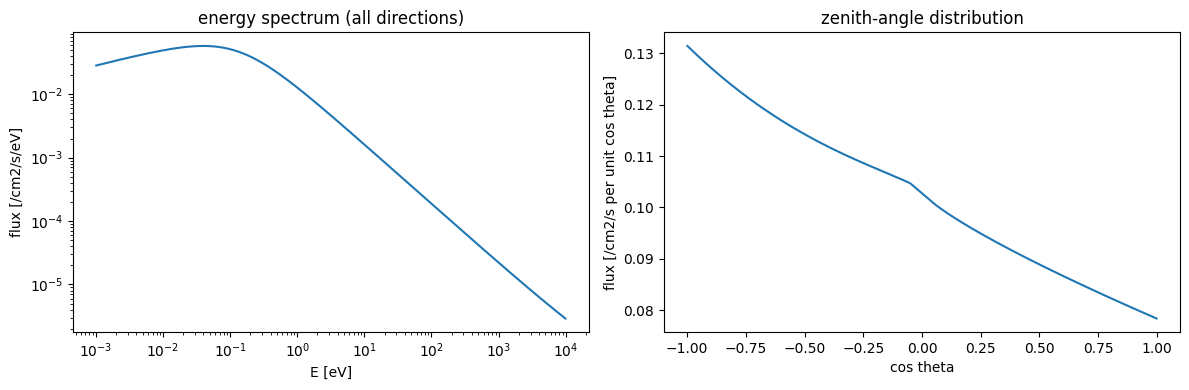

In [2]:
src = cfg["source"]["parameters"]
f = ROOT.TFile.Open(src["flux_file"])
h = f.Get("h2d0")                         # 中性子
nx, ny = h.GetNbinsX(), h.GetNbinsY()
E = np.array([h.GetXaxis().GetBinCenter(i + 1) for i in range(nx)])           # MeV
dE = np.array([h.GetXaxis().GetBinWidth(i + 1) for i in range(nx)])
cos = np.array([h.GetYaxis().GetBinCenter(j + 1) for j in range(ny)])
dcos = np.array([h.GetYaxis().GetBinWidth(j + 1) for j in range(ny)])
z = np.array([[h.GetBinContent(i + 1, j + 1) for j in range(ny)] for i in range(nx)])  # /cm2/s/sr/MeV
w = z * dE[:, None] * dcos[None, :] * 2 * np.pi                                       # /cm2/s
print(f"{h.GetTitle()}: E {h.GetXaxis().GetXmin():g}〜{h.GetXaxis().GetXmax():g} MeV, TotalFlux = {w.sum():.4g} /cm2/s")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(E * 1e6, w.sum(axis=1) / dE / 1e6); ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("E [eV]"); ax[0].set_ylabel("flux [/cm2/s/eV]"); ax[0].set_title("energy spectrum (all directions)")
ax[1].plot(cos, w.sum(axis=0) / dcos); ax[1].set_xlabel("cos theta"); ax[1].set_ylabel("flux [/cm2/s per unit cos theta]")
ax[1].set_title("zenith-angle distribution")
fig.tight_layout(); plt.show()

cosθ は、そのまま粒子の **進む向き** の z 成分になります(参照の `SMILE_2p_PA_CR` と同じ)。
検出器の座標系の z は鉛直下向きです(底面の HA が z の大きい側、`../1_SMILE2pGeometry/`)。なので cosθ < 0 は上向きに進む粒子、cosθ > 0 は下向きに進む粒子です。

エネルギーを落としたイベントの一次粒子の位置は、原点から `plane_distance` 離れた面の上にあります。

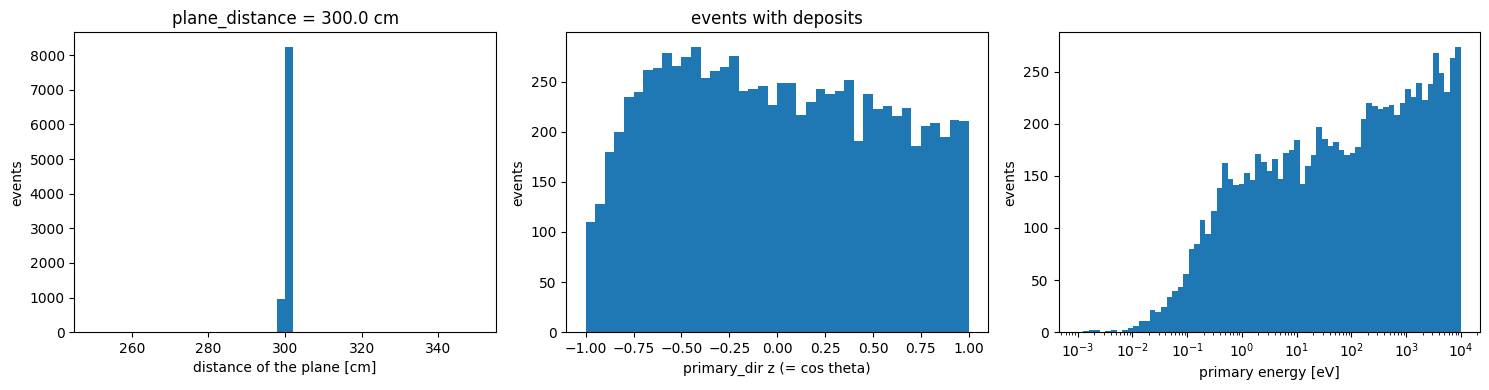

In [3]:
d = ROOT.RDataFrame("edep", str(EDEP)).AsNumpy(["primary_pos", "primary_dir", "primary_energy"])
pos = np.stack([np.asarray(v) for v in d["primary_pos"]]); dirv = np.stack([np.asarray(v) for v in d["primary_dir"]])
dist = -np.sum(pos * dirv, axis=1)          # 面までの距離 = 位置の、進む向きと逆向きの成分 [mm]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(dist / 10, bins=50, range=(src["plane_distance"] - 50, src["plane_distance"] + 50)); ax[0].set_xlabel("distance of the plane [cm]"); ax[0].set_title(f"plane_distance = {src['plane_distance']} cm")
ax[1].hist(dirv[:, 2], bins=40, range=(-1, 1)); ax[1].set_xlabel("primary_dir z (= cos theta)"); ax[1].set_title("events with deposits")
ax[2].hist(d["primary_energy"] * 1e3, bins=np.logspace(-3, 4, 70)); ax[2].set_xscale("log"); ax[2].set_xlabel("primary energy [eV]")
for a in ax: a.set_ylabel("events")
fig.tight_layout(); plt.show()

- 左: どのイベントも面までの距離が `plane_distance`(300 cm)で、面が方向に合わせて回っていることが分かります。
- 中・右: エネルギーを落としたイベントだけなので、入力のフラックスの形とは違います(検出器に届いて反応しやすいものが残る)。